# Age prediction from faces (CNN)

## The data

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_PATH = "../data/UTKFace"

files = os.listdir(DATA_PATH)
print(len(files))
print(files[:5])

23708
['100_0_0_20170112213500903.jpg.chip.jpg', '100_0_0_20170112215240346.jpg.chip.jpg', '100_1_0_20170110183726390.jpg.chip.jpg', '100_1_0_20170112213001988.jpg.chip.jpg', '100_1_0_20170112213303693.jpg.chip.jpg']


## Load the data
Open every image, make it 64x64 RGB, and take the age from the file name. I used 64x64 to keep the memory small (my laptop isn't strong) and the faces are still clear enough. Ages go from 1 to 116, the histogram shows how they are spread.

(23708, 64, 64, 3) (23708,) 1.0 116.0


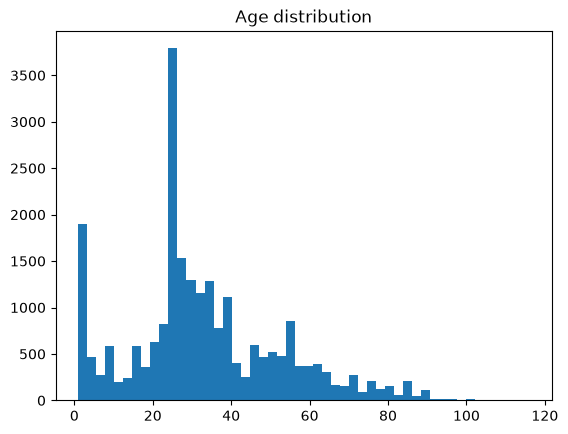

In [9]:
IMG_SIZE = 64
X = []
y = []

for f in files:
    if not f.endswith(".jpg"):
        continue
    age = int(f.split("_")[0])
    img = Image.open(os.path.join(DATA_PATH, f)).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    X.append(np.array(img))
    y.append(age)

X = np.array(X, dtype="uint8")
y = np.array(y, dtype="float32")
print(X.shape, y.shape, y.min(), y.max())

plt.hist(y, bins=50)
plt.title("Age distribution")
plt.show()

## Train / validation / test split


**Baseline:** always predicting the average age gives an MAE of **15.4 years**. Any model has to beat this.

In [10]:
from sklearn.model_selection import train_test_split


X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.20, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

baseline_mae = np.mean(np.abs(y_test - y_train.mean()))
print("Baseline MAE (always predict the mean age):", baseline_mae)

(15172, 64, 64, 3) (3794, 64, 64, 3) (4742, 64, 64, 3)
Baseline MAE (always predict the mean age): 15.421968


## First CNN
3 conv blocks (32 → 64 → 128 filters) with `MaxPooling(3,3)`, then Dense 1024 and one output neuron for the age. The loss is MAE because that is the metric I care about. 226k parameters.

In [11]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Rescaling, RandomFlip, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


model = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    Rescaling(1/255),

    Conv2D(32, 3, activation="relu"),
    MaxPooling2D(3,3),

    Conv2D(64, 3, activation="relu"),
    MaxPooling2D(3,3),

    Conv2D(128, 3, activation="relu"),
    MaxPooling2D(3,3),

    Flatten(),
    Dense(1024, activation='relu'),
    Dense(1)
])

model.compile(optimizer="adam", loss="mae", metrics=["mae"])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 18, 18, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │       132,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,369 (884.25 KB)

 Trainable params: 226,369 (884.25 KB)

 Non-trainable params: 0 (0.00 B)

Early stopping on `val_mae` with patience 3, and `restore_best_weights=True` so I keep the best epoch and not the last one.

In [13]:
early_stop = EarlyStopping(monitor="val_mae", patience=3, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - loss: 7.0700 - mae: 7.0700 - val_loss: 7.9903 - val_mae: 7.9903
Epoch 2/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 6.8702 - mae: 6.8702 - val_loss: 9.1458 - val_mae: 9.1458
Epoch 3/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 6.5907 - mae: 6.5907 - val_loss: 8.4533 - val_mae: 8.4533
Epoch 4/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 6.3647 - mae: 6.3647 - val_loss: 7.4073 - val_mae: 7.4073
Epoch 5/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - loss: 6.1921 - mae: 6.1921 - val_loss: 7.5265 - val_mae: 7.5265
Epoch 6/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 6.1110 - mae: 6.1110 - val_loss: 7.1836 - val_mae: 7.1836
Epoch 7/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 5.9549 - mae: 5.9549 - val_loss: 7.5846 - val_mae: 7.5846
Epoch 8/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 5.7700 - mae: 5.7700 - val_loss: 7.3592 - val_mae: 7.3592
Epoch 9/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 

### Result of the first model
Stopped at epoch 9, best val MAE was 7.18 (epoch 6). Train MAE kept going down (5.7) while validation stayed around 7.2 - 7.5, so there is a little overfitting.

Test MAE is **7.31** vs 15.42 for the baseline, already less than half of the error.

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 7.3081 - mae: 7.3081
Test MAE: 7.308111190795898 | Baseline MAE: 15.421968


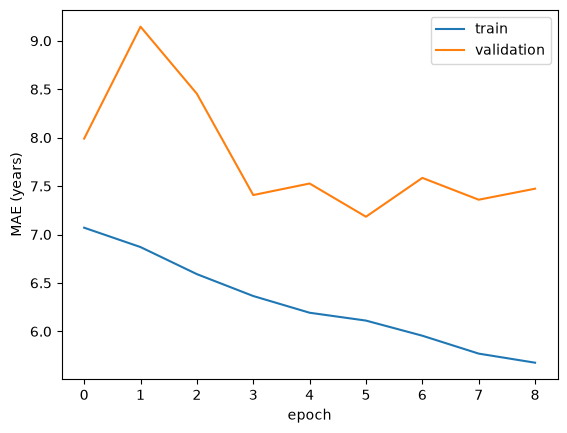

In [14]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print("Test MAE:", test_mae, "| Baseline MAE:", baseline_mae)

plt.plot(history.history["mae"], label="train")
plt.plot(history.history["val_mae"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MAE (years)")
plt.legend()
plt.show()

## Better CNN (`imodel`)
The problem with the first one: `MaxPooling(3,3)` three times shrinks the image to 1x1x128, so the model keeps only 128 numbers for the whole face.

Fix: `MaxPooling(2)` with `padding='same'`, so the feature map ends at 8x8x128 (8192 features). Parameters go up to 8.5M, almost all of them in the Dense layer.

In [15]:
imodel = Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    Rescaling(1/255),

    Conv2D(32, 3, activation="relu", padding='same'),
    MaxPooling2D(2),

    Conv2D(64, 3, activation="relu", padding='same'),
    MaxPooling2D(2),

    Conv2D(128, 3, activation="relu", padding='same'),
    MaxPooling2D(2),

    Flatten(),
    Dense(1024, activation='relu'),
    Dense(1)
])

imodel.compile(optimizer="adam", loss="mae", metrics=["mae"])

imodel.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1024)           │     8,389,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,483,905 (32.36 MB)

 Trainable params: 8,483,905 (32.36 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
ihistory = imodel.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 46s 95ms/step - loss: 14.2175 - mae: 14.2175 - val_loss: 11.9080 - val_mae: 11.9080
Epoch 2/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 44s 93ms/step - loss: 10.3535 - mae: 10.3535 - val_loss: 9.7089 - val_mae: 9.7089
Epoch 3/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 44s 93ms/step - loss: 8.8681 - mae: 8.8681 - val_loss: 9.5857 - val_mae: 9.5857
Epoch 4/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 44s 92ms/step - loss: 8.0326 - mae: 8.0326 - val_loss: 7.8865 - val_mae: 7.8865
Epoch 5/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 44s 92ms/step - loss: 7.4864 - mae: 7.4864 - val_loss: 7.6720 - val_mae: 7.6720
Epoch 6/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 44s 94ms/step - loss: 7.1247 - mae: 7.1247 - val_loss: 8.4416 - val_mae: 8.4416
Epoch 7/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 44s 93ms/step - loss: 6.9580 - mae: 6.9580 - val_loss: 7.2847 - val_mae: 7.2847
Epoch 8/30
475/475 ━━━━━━━━━━━━━━━━━━━━ 44s 92ms/step - loss: 6.4084 - mae: 6.4084 - val_loss: 7.0490 - val_mae: 7.0490
Epoch 9/30
475/475 ━━━━━━━━━━━━━━━

> 6.8 is the best val_mae I got 

149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 6.8418 - mae: 6.8418
Test MAE: 6.841833114624023 | Baseline MAE: 15.421968


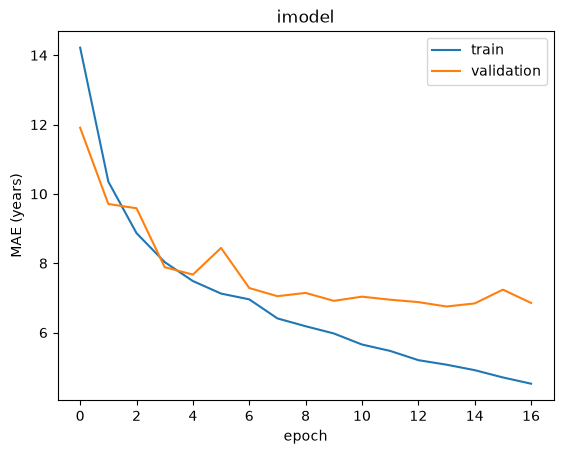

In [20]:
test_loss, test_mae = imodel.evaluate(X_test, y_test)
print("Test MAE:", test_mae, "| Baseline MAE:", baseline_mae)

plt.plot(ihistory.history["mae"], label="train")
plt.plot(ihistory.history["val_mae"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MAE (years)")
plt.title("imodel")
plt.legend()
plt.show()

## Error analysis
`imodel` stopped at epoch 17, best val MAE was 6.75 (epoch 14). Test MAE is **6.84**, better than the first CNN (7.31) and the baseline (15.42). This is the final model.

Now, where does it make mistakes? Scatter plot of actual vs predicted age, and the MAE for each age group.

149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step


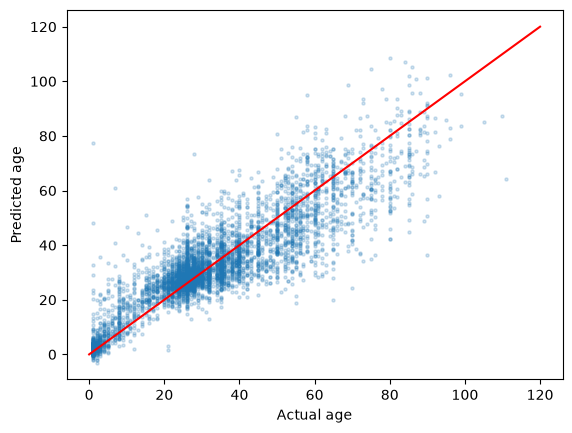

0-10: MAE = 4.3  (n=602)
10-20: MAE = 7.4  (n=284)
20-30: MAE = 4.8  (n=1489)
30-40: MAE = 5.6  (n=883)
40-50: MAE = 7.9  (n=438)
50-60: MAE = 10.1  (n=477)
60-80: MAE = 12.1  (n=428)
80-120: MAE = 15.3  (n=141)


In [21]:
y_pred = imodel.predict(X_test).flatten()

plt.scatter(y_test, y_pred, alpha=0.2, s=5)
plt.plot([0, 120], [0, 120], color="red")
plt.xlabel("Actual age")
plt.ylabel("Predicted age")
plt.show()

bins = [0, 10, 20, 30, 40, 50, 60, 80, 120]
age_group = np.digitize(y_test, bins)
for g in np.unique(age_group):
    mask = age_group == g
    print(f"{bins[g-1]}-{bins[g]}: MAE = {np.mean(np.abs(y_test[mask] - y_pred[mask])):.1f}  (n={mask.sum()})")

### What I see
- Error is smallest for kids (0-10: 4.3 years) and for 20-30 (4.8).
- It grows with age: 50-60 is 10.1, 60-80 is 12.1, and 80+ is 15.3.
- 80+ has only 141 test images, so the model probably doesn't see enough old faces and pulls its predictions toward the middle ages.
- 10-20 is also harder than its neighbours (7.4), teenagers are hard to tell apart from young adults.

## Save the model
Saved as `age_model.keras`. The Streamlit app (`age_app.py`) loads it.

In [22]:
imodel.save("age_model.keras")

## Conclusion
- The CNN predicts age with an average error of about **6.8 years** (baseline 15.4).
- Smaller pooling made the biggest difference (7.31 → 6.84).
- It is weak on older people, and it only works well on close-up cropped faces like the training data.
- Next steps: data augmentation, dropout / batch normalization, bigger images, or transfer learning.